# May 26

## Large model 1 shot

In [1]:
import pickle 
from glob import glob 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import utils
from collections import defaultdict
import gpt

utils.set_plot_style()




/tmp/ipykernel_3694997/1502289027.py:3: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [ ]:
 
#### 1. What Was Done (Commendations & Analysis)

* **Generalizing Feature Covariance ($\psi$ vs. $\varphi$)**:
  In [`Initialization/DeepNNGPTheorems.lean`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/DeepNNGPTheorems.lean#L614), proving [`deepEmpiricalFeatureCovariance_tendstoInMeasure`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/DeepNNGPTheorems.lean#L614) for an arbitrary feature map $\psi : \mathbb{R} \to \mathbb{R}$ while the recurrence runs on $\varphi$ was the right architectural design choice. It allowed:
  * [`deepEmpiricalCovariance_tendstoInMeasure`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/DeepNNGPTheorems.lean#L590) to be instantiated with $\psi = \varphi$.
  * [`deepDerivativeGram_entry_tendstoInMeasure`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Deep/GaussianDecoupling.lean#L188) to be instantiated with $\psi = \varphi'$ at zero extra proof cost.
* **Prefix Measure Transport Extraction**:
  Extracting [`tendstoInMeasure_prod_of_prefix`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Deep/GaussianDecoupling.lean#L117) avoided 25 lines of duplicate measure-preserving proof boilerplate between `deepActivationGram` and `deepDerivativeGram`.
* **Clean Splitting of Random Matrix Theory**:
  Moving matrix algebra out to [`Initialization/GaussianMatrixAlgebra.lean`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/GaussianMatrixAlgebra.lean) (462 lines) keeps [`GaussianDecoupling.lean`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Deep/GaussianDecoupling.lean) focused strictly on network-specific decoupling.
* **Continuous Integration**:
  The new [`.github/workflows/build.yml`](file:///jukebox/norman/qanguyen/autoform/LML/.github/workflows/build.yml) brings automated checking of Lean compilation, linting, docs, and the blueprint.

---
 

#### 3. Guidance & Blueprint for the Final Remaining Lemma: `deepSensitivityGram_entry_tendstoInMeasure`

To prove [`deepSensitivityGram_entry_tendstoInMeasure`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Deep/GaussianDecoupling.lean#L253), structure the proof as downward induction on $k \in \{0, \dots, d - 1\}$:

##### Stage A: Readout Base Case ($k = d - 1$)
1. **Algebraic Identity**:
   By [`backwardSensitivity_top`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Deep/Architecture.lean#L274), at layer $d - 1$:
   $$g_{d-1}^\alpha(j) = W_{d,j} \cdot \varphi'(h_{d-1,j}^\alpha)$$
   Therefore, the empirical backward Gram entry is:
   $$G_{d-1}^{(n), \alpha\beta} = \frac{1}{n}\sum_{j=1}^n W_{d,j}^2 \, \varphi'(h_{d-1,j}^\alpha) \varphi'(h_{d-1,j}^\beta)$$
   Splitting $W_{d,j}^2 = (W_{d,j}^2 - 1) + 1$:
   $$G_{d-1}^{(n), \alpha\beta} = \underbrace{\frac{1}{n} \sum_{j=1}^n (W_{d,j}^2 - 1) y_j}_{\Delta_n} + \underbrace{\frac{1}{n}\sum_{j=1}^n \varphi'(h_{d-1,j}^\alpha)\varphi'(h_{d-1,j}^\beta)}_{\Phi'_{d-1, \alpha\beta}^{(n)}}$$
   where $y_j = \varphi'(h_{d-1,j}^\alpha)\varphi'(h_{d-1,j}^\beta)$.
2. **Connecting to Working Tree Lemmas**:
   * Conditionally on the hidden weights $W$, the readout weights $a = W_d$ are drawn from $\prod_{j=1}^n \mathcal{N}(0, 1)$.
   * Applying [`chebyshev_centeredSquare_weighted`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/ConditionalConcentration.lean#L252) gives:
     $$\sigma_n(W) \le \frac{C}{n \varepsilon^2} \left(\frac{1}{n}\sum_{j=1}^n y_j^2\right)$$
   * Because $\frac{1}{n}\sum_j y_j^2$ converges in measure (by [`deepEmpiricalFeatureCovariance_tendstoInMeasure`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/DeepNNGPTheorems.lean#L614) with $\psi = (\varphi')^2$), it is bounded on an exceptional set $E_n$ with $\mathbb{P}(E_n) \to 0$.
   * Applying [`tendsto_of_lintegral_section_bound`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/ConditionalConcentration.lean#L45) proves $\Delta_n \xrightarrow{\mathbb{P}} 0$.
3. **Closing the Base Case**:
   Combine $\Delta_n \xrightarrow{\mathbb{P}} 0$ with [`deepDerivativeGram_entry_tendstoInMeasure`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Deep/GaussianDecoupling.lean#L188) ($\Phi'_{d-1, \alpha\beta}^{(n)} \xrightarrow{\mathbb{P}} \dot{\Sigma}^{d-1}_{\alpha\beta}$) using the triangle-inequality squeeze [`NTK.tendstoInMeasure_trans`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/DeepRecursion.lean#L352):
   $$G_{d-1}^{(n), \alpha\beta} \xrightarrow{\mathbb{P}} \dot{\Sigma}^{d-1}_{\alpha\beta} = \Pi^{d-1}_{\alpha\beta}$$

##### Stage B: Downward Inductive Step ($k < d - 1$)
1. **Algebraic Form of the Step**:
   By [`backwardSensitivity_step`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Deep/Architecture.lean#L282):
   $$g_k^\alpha = \frac{1}{\sqrt{n}} D_k^\alpha W_k^\top g_{k+1}^\alpha, \quad D_k^\alpha = \operatorname{diag}(\varphi'(h_k^\alpha))$$
   Thus, with $A = D_k^\alpha D_k^\beta = \operatorname{diag}(\varphi'(h_k^\alpha) \odot \varphi'(h_k^\beta))$:
   $$G_k^{(n), \alpha\beta} = \frac{1}{n^2} (g_{k+1}^\alpha)^\top W_k A W_k^\top g_{k+1}^\beta$$
2. **Decomposition via Lemma 2.26**:
   * Decompose $W_k = W_k P + W_k P^\perp$ via [`orthogonalDecomposition`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Foundations/MatrixUtil.lean#L414) where $P$ projects onto $\operatorname{span}\{\varphi(h_k^1), \dots, \varphi(h_k^m)\}$.
   * By [`indepFun_conditioned_weight_history`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/GaussianMatrixAlgebra.lean#L440), $W_k P^\perp$ is independent of the forward history up to layer $k$ and therefore independent of $g_{k+1}$.
   * Since $\operatorname{rank}(P) \le m$, the contribution from $W_k P$ is $O(m/n) \to 0$.
3. **Normalized Bilinear Expectation**:
   By [`backward_empirical_quadForm_asymptotic_limit`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/GaussianMatrixAlgebra.lean#L299):
   $$\mathbb{E}_{W_k}\left[\frac{1}{n^2} (g_{k+1}^\alpha)^\top W_k A W_k^\top g_{k+1}^\beta\right] = \left(\frac{1}{n} g_{k+1}^\alpha \cdot g_{k+1}^\beta\right) \left(\frac{1}{n} \operatorname{tr}(A)\right) = G_{k+1}^{(n), \alpha\beta} \cdot \Phi'_{k, \alpha\beta}^{(n)}$$
4. **Induction Squeeze**:
   * Induction hypothesis: $G_{k+1}^{(n), \alpha\beta} \xrightarrow{\mathbb{P}} \Pi^{k+1}_{\alpha\beta}$.
   * Derivative Gram limit: $\Phi'_{k, \alpha\beta}^{(n)} \xrightarrow{\mathbb{P}} \dot{\Sigma}^k_{\alpha\beta}$.
   * By [`tendstoInMeasure_sum_mul`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/DeepRecursion.lean#L420), their product converges in measure to:
     $$\Pi^{k+1}_{\alpha\beta} \cdot \dot{\Sigma}^k_{\alpha\beta} = \Pi^k_{\alpha\beta}$$

---

#### 4. Reusability, Prior Work Reuse, & Refactoring Opportunities

1. **Reuse Existing Mathlib and Repository Declarations**:
   * **Moment Integrability**: Do not reprove the 4th Gaussian moment; [`NTK.integrable_pow_four_gaussianReal`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Foundations/Concentration.lean#L46) is already proved in `Foundations/Concentration.lean`.
   * **Product Independence**: For evaluating expectations of independent products, use Mathlib's [`ProbabilityTheory.IndepFun.integral_fun_mul_eq_mul_integral`](https://leanprover-community.github.io/mathlib4_docs/Mathlib/Probability/Independence/Integration.html#ProbabilityTheory.IndepFun.integral_fun_mul_eq_mul_integral).
   * **Metric Squeeze**: For assembling sums of limits in measure, use [`NTK.tendstoInMeasure_trans`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/DeepRecursion.lean#L352).
2. **Fix Long-Line Linter Warnings Before Pushing**:
   Since `.github/workflows/build.yml` runs with `lint: true`, the following lines exceed the 100-character style limit and will fail CI:
   * In [`GaussianDecoupling.lean`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Deep/GaussianDecoupling.lean): lines 114, 115, 181, 183, 184, 201 (wrap docstrings and theorem parameter lines).
   * In [`ConditionalConcentration.lean`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/ConditionalConcentration.lean): lines 22, 24, 42, 260, 266, 286 (e.g. line 286: break `rw [integral_finsetSum ...]` across two lines).
3. **Generalize Fourth-Power Variance**:
   In [`ConditionalConcentration.lean`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/ConditionalConcentration.lean#L243), [`gaussianSqCenteredVariance`](file:///jukebox/norman/qanguyen/autoform/LML/LeanMachineLearning/Optimization/NTK/Initialization/ConditionalConcentration.lean#L243) is defined as `Var[fun x : ℝ => x ^ 2 - 1; gaussianReal 0 1]`. Proving a one-line lemma `0 ≤ gaussianSqCenteredVariance` via `variance_nonneg` will avoid needing to unpack the definition in subsequent inequality tactics.

In [2]:
folders = glob("/scratch/qanguyen/gautam/cache/memo_may25_zipf_onelayerattention_large_noresample/*")
# folders = glob("/scratch/qanguyen/gautam/cache/memo_nov10_zipf_gpt2_vary_num_hidden_features_num_heads_doresample/*")
df = defaultdict(list)
for folder in folders:
    pkl = glob(f"{folder}/*")
    run_name = [p for p in pkl if ("model_iter" not in p) and ("sequences" not in p)][0].split("/")[-1] 
    print("run_name", run_name)
    fname = f"{folder}/{run_name}"
    print("fname", fname)
    with open(fname, "rb") as f:
        data = utils.CPU_Unpickler(f).load()
    if "logs" not in data:
        continue
    get_model = lambda: gpt.OneLayerAttention(data["args"]["len_context"], 
                                  data["args"]["num_heads"], 
                                  data["args"]["num_hidden_features"], 
                                  data["args"]["vocab_size"], 
                                  data["args"]["num_mlp_layers"],
                                  is_initialize_attention_weights_to_zero=data["args"]["is_initialize_attention_weights_to_zero"],
                                  ) 
    model = get_model() 
    num_parameters = sum(p.numel() for k, p in model.state_dict().items())
    print("len(data['logs'])", len(data["logs"]), "arch", data["args"]["arch"], "num_parameters", num_parameters / 1e6, "num_layers", data["args"]["num_layers"], "num_heads", data["args"]["num_heads"], "num_hidden_features", data["args"]["num_hidden_features"])
    # if num_parameters > 1e6 and data["logs"][-1]["train_loss"] > 0.3:
    #     continue
    # if num_parameters > 7e7:
    #     continue
    # if len(data["logs"]) < 10:
    #     continue
    num_hidden_features = data["args"]["num_hidden_features"]
    num_heads = data["args"]["num_heads"] 
    num_appearances_at_39 = None
    for l in data["logs"]:
        
        
        test_metrics = l["test_metrics"]
        sequence_ranks = test_metrics["sequence_rank"]  # * 10 
        # print("len(sequence_ranks)", len(sequence_ranks))
        num_appearances = l["num_apppearances"][sequence_ranks]
        accuracy = test_metrics["accuracy"] 
        # if num_appearances_at_39 is not None:
            # num_appearances -= num_appearances_at_39
        df["num_appearances"].extend(num_appearances)
        df["sequence_rank"].extend(sequence_ranks)
        df["accuracy"].extend(accuracy)
        df["num_parameters"].extend([ num_parameters ] * len(num_appearances))
        df["epoch"].extend([l["epoch"]] * len(num_appearances))  
        df["switch_number"].extend([int (1)] * len(num_appearances))   

run_name memo_may25_zipf_onelayerattention_large_noresample_transformer_K_500000_L_100_hidden_512_nheads_13_nlayers_12_1780095638.1662905.pkl
fname /scratch/qanguyen/gautam/cache/memo_may25_zipf_onelayerattention_large_noresample/memo_may25_zipf_onelayerattention_large_noresample_transformer_K_500000_L_100_hidden_512_nheads_13_nlayers_12_1780095638.1662905/memo_may25_zipf_onelayerattention_large_noresample_transformer_K_500000_L_100_hidden_512_nheads_13_nlayers_12_1780095638.1662905.pkl
len(data['logs']) 71 arch OneLayerAttention num_parameters 266.572802 num_layers 12 num_heads 13 num_hidden_features 512
run_name memo_may25_zipf_onelayerattention_large_noresample_transformer_K_500000_L_100_hidden_256_nheads_16_nlayers_12_1780095637.9330964.pkl
fname /scratch/qanguyen/gautam/cache/memo_may25_zipf_onelayerattention_large_noresample/memo_may25_zipf_onelayerattention_large_noresample_transformer_K_500000_L_100_hidden_256_nheads_16_nlayers_12_1780095637.9330964/memo_may25_zipf_onelayeratte

In [3]:
THRESHOLD = 0.9
_df = pd.DataFrame(df)
cols = ['num_appearances', 'sequence_rank', 'accuracy', 'num_parameters', 'epoch', 'num_appearances_at_saturation']
results = []
df_capacity = defaultdict(list)
for switch_number in _df["switch_number"].unique():
    for num_parameter in _df["num_parameters"].unique():
        # Filter by parameter count
        subdf = _df[np.abs(_df["num_parameters"] - num_parameter) < 1e-2].copy()
        subdf = subdf[subdf["switch_number"] == switch_number]
        # display(subdf)
        
        # 1. Identify which ranks ever reached the threshold
        ranks_that_met_90 = subdf.loc[subdf["accuracy"] > THRESHOLD, "sequence_rank"].unique()
        
        # 2. Extract rows for ranks that met 90% (get the MIN epoch where accuracy > 0.9)
        df_met = (
            subdf[(subdf["sequence_rank"].isin(ranks_that_met_90)) & (subdf["accuracy"] > THRESHOLD)]
            .sort_values("epoch", ascending=True)
            .drop_duplicates("sequence_rank")
        )
        # df_met["num_appearances_at_saturation"] = df_met["num_appearances"]
        assert "switch_number" in df_met, "df_met doesn't have switch_number"
        df_capacity["num_parameters"].extend([num_parameter])
        df_capacity["max_rank_at_saturation"].extend([df_met["sequence_rank"].max()])
        # display("num_parameter", num_parameter, "df_met", df_met)
        # 3. Extract rows for ranks that NEVER met 90% (get the MAX epoch available)
        # df_never_met = (
        #     subdf[~subdf["sequence_rank"].isin(ranks_that_met_90)]
        #     .sort_values("epoch", ascending=False)
        #     .drop_duplicates("sequence_rank")
        # )
        # df_never_met["num_appearances_at_saturation"] = 1e5
        # 4. Combine and filter for requested columns
        result_epochs = (
            pd.concat([df_met])
            .sort_values("sequence_rank")
        )
        results.append(result_epochs)

In [4]:
results = pd.concat(results)
display(results)
_df = pd.DataFrame(df)
display(_df)


,num_appearances,sequence_rank,accuracy,num_parameters,epoch,switch_number
7040000,410546.0,0,0.919192,266572802,22,1
9600001,50845.0,10,0.909091,266572802,30,1
12480002,34740.0,20,0.929293,266572802,39,1
11200003,21328.0,30,0.939394,266572802,35,1
11520004,16333.0,40,0.919192,266572802,36,1
...,...,...,...,...,...,...
272323801,37.0,38010,0.939394,66832898,76,1
281604179,58.0,41790,0.909091,66832898,105,1
261124325,20.0,43250,0.909091,66832898,41,1
264324349,32.0,43490,0.919192,66832898,51,1


,num_appearances,sequence_rank,accuracy,num_parameters,epoch,switch_number
0,0.0,0,0.545455,266572802,0,1
1,0.0,10,0.494949,266572802,0,1
2,0.0,20,0.444444,266572802,0,1
3,0.0,30,0.515152,266572802,0,1
4,0.0,40,0.454545,266572802,0,1
...,...,...,...,...,...,...
337919995,9.0,499995,0.484848,66832898,280,1
337919996,12.0,499996,0.444444,66832898,280,1
337919997,8.0,499997,0.515152,66832898,280,1
337919998,9.0,499998,0.515152,66832898,280,1


In [ ]:
results = 

,num_appearances,sequence_rank,accuracy,num_parameters,epoch,switch_number
7040000,410546.0,0,0.919192,266572802,22,1
9600001,50845.0,10,0.909091,266572802,30,1
12480002,34740.0,20,0.929293,266572802,39,1
11200003,21328.0,30,0.939394,266572802,35,1
11520004,16333.0,40,0.919192,266572802,36,1
...,...,...,...,...,...,...
272323801,37.0,38010,0.939394,66832898,76,1
281604179,58.0,41790,0.909091,66832898,105,1
261124325,20.0,43250,0.909091,66832898,41,1
264324349,32.0,43490,0.919192,66832898,51,1


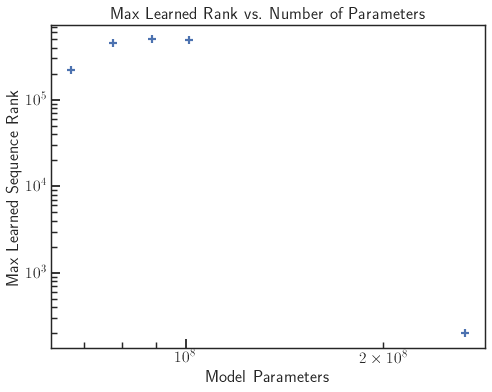

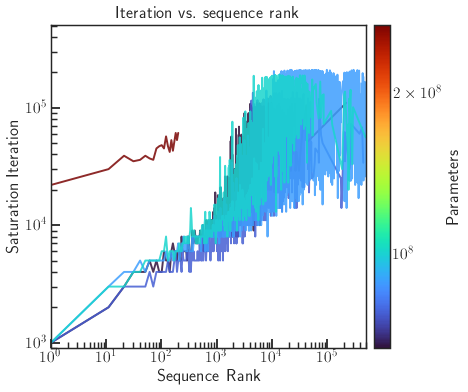

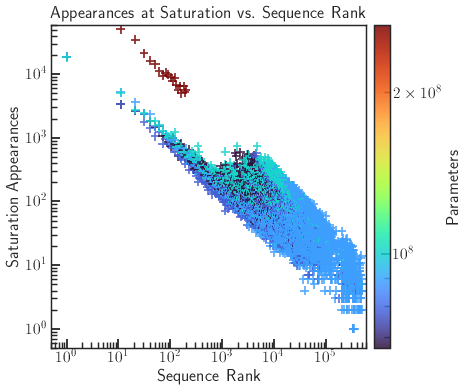

In [7]:
# plot the max rank at saturation vs num parameters
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
plt.scatter(df_capacity["num_parameters"], df_capacity["max_rank_at_saturation"],
    s=70, marker="+")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Model Parameters")
plt.ylabel("Max Learned Sequence Rank")
plt.title("Max Learned Rank vs. Number of Parameters")
plt.show()

from matplotlib.colors import LogNorm
import matplotlib.ticker as mticker

# plot the saturation time vs sequence rank
def compute_saturation_time(row):
    time = row["epoch"]
    if row["switch_number"] == 1:
        return time * 1000
    else:
        return (time - (row["switch_number"] - 1) * 40) * 1000

results["iters"] = results.apply(compute_saturation_time, axis=1)
results["sequence_rank_plus_one"] = results["sequence_rank"] + 1

fig, axs = plt.subplots(1, 1, figsize=(7, 6))
axs = [axs]

plot_results = results[results["switch_number"].isin(range(1, 2))].copy()
plot_results["num_parameters"] = pd.to_numeric(plot_results["num_parameters"])
plot_results["sequence_rank_plus_one"] = pd.to_numeric(plot_results["sequence_rank_plus_one"])

norm = LogNorm(
    vmin=plot_results["num_parameters"].min(),
    vmax=plot_results["num_parameters"].max(),
)

for i, switch_number in enumerate(range(1, 2)):
    subresults = plot_results[plot_results["switch_number"] == switch_number].copy()
    subresults = subresults.sort_values(["num_parameters", "sequence_rank_plus_one"])

    sns.lineplot(
        data=subresults,
        x="sequence_rank_plus_one",
        y="iters",
        hue="num_parameters",
        palette="turbo",
        hue_norm=norm,
        linewidth=2.0,
        alpha=0.85,
        legend=False,
        ax=axs[i]
    )

    axs[i].set_title("Iteration vs. sequence rank")
    axs[i].set_xscale("log")
    axs[i].set_xlim(1, 510000)
    axs[i].set_ylim(900, 510000)
    axs[i].set_yscale("log")
    axs[i].set_xlabel("Sequence Rank")
    axs[i].set_ylabel("Saturation Iteration")

sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axs[0], pad=0.02)
cbar.set_label("Parameters")
cbar.formatter = mticker.LogFormatterSciNotation()
cbar.update_ticks()
 
plt.show()

fig, axs = plt.subplots(1, 1, figsize=(7, 6))
axs = [axs]

plot_results = results[results["switch_number"].isin(range(1, 2))].copy()
plot_results["num_parameters"] = pd.to_numeric(plot_results["num_parameters"])
plot_results["sequence_rank_plus_one"] = pd.to_numeric(plot_results["sequence_rank_plus_one"])

norm = LogNorm(
    vmin=plot_results["num_parameters"].min(),
    vmax=plot_results["num_parameters"].max(),
)

sc = None
for i, switch_number in enumerate(range(1, 2)):
    subresults = plot_results[plot_results["switch_number"] == switch_number].copy()
    subresults = subresults.sort_values(
        ["sequence_rank_plus_one", "num_parameters"],
        ignore_index=True,
    )

    sc = axs[i].scatter(
        subresults["sequence_rank_plus_one"],
        subresults["num_appearances"],
        c=subresults["num_parameters"],
        cmap="turbo",
        norm=norm,
        linewidths=1.8,
        alpha=0.85,
        marker="+",
    )

    axs[i].set_title("Appearances at Saturation vs. Sequence Rank")
    axs[i].set_xscale("log")
    axs[i].set_xlim(0.5, 600000)
    axs[i].set_ylim(0.5, 60000)
    axs[i].set_yscale("log")
    axs[i].set_xlabel("Sequence Rank")
    axs[i].set_ylabel("Saturation Appearances")

cbar = fig.colorbar(sc, ax=axs[0], pad=0.02)
cbar.set_label("Parameters")
cbar.formatter = mticker.LogFormatterSciNotation()
cbar.update_ticks()
 
plt.show()


## Large model 1 shot switch

In [6]:
import pickle 
from glob import glob 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import utils
from collections import defaultdict
import gpt

utils.set_plot_style()




In [7]:
folders = glob("/scratch/qanguyen/gautam/cache/memo_may25_zipf_onelayerattention_large_doresample/*")
df = defaultdict(list)
total_epochs = 300
for folder in folders:
    pkl = glob(f"{folder}/*")
    run_name = [p for p in pkl if ("model_iter" not in p) and ("sequences" not in p)][0].split("/")[-1] 
    print("run_name", run_name)
    fname = f"{folder}/{run_name}"
    print("fname", fname)
    with open(fname, "rb") as f:
        data = utils.CPU_Unpickler(f).load()
    if "logs" not in data:
        continue
    get_model = lambda: gpt.OneLayerAttention(data["args"]["len_context"], 
                                  data["args"]["num_heads"], 
                                  data["args"]["num_hidden_features"], 
                                  data["args"]["vocab_size"], 
                                  data["args"]["num_mlp_layers"],
                                  is_initialize_attention_weights_to_zero=data["args"]["is_initialize_attention_weights_to_zero"],
                                  ) 
    model = get_model() 
    num_parameters = sum(p.numel() for k, p in model.state_dict().items())
    print("len(data['logs'])", len(data["logs"]), "key", data["logs"][0].keys(), "arch", data["args"]["arch"], "num_parameters", num_parameters, "num_layers", data["args"]["num_layers"], "num_heads", data["args"]["num_heads"], "num_hidden_features", data["args"]["num_hidden_features"])
    
    num_hidden_features = data["args"]["num_hidden_features"]
    num_heads = data["args"]["num_heads"] 
    for l in data["logs"]:
        test_metrics = l["test_metrics"]
        sequence_ranks = test_metrics["sequence_rank"] 
        accuracy = test_metrics["accuracy"] 
        # if num_appearances_at_39 is not None:
            # num_appearances -= num_appearances_at_39
        num_appearances = l["num_apppearances"][sequence_ranks]
        df["num_appearances"].extend(num_appearances)
        df["sequence_rank"].extend(sequence_ranks)
        df["accuracy"].extend(accuracy)
        df["num_parameters"].extend([ num_parameters ] * len(num_appearances))
        df["epoch"].extend([l["epoch"]] * len(num_appearances))  
        df["switch_number"].extend([int (l["epoch"] // (total_epochs / 2.0)+1.0)] * len(num_appearances))  
         

run_name memo_may25_zipf_onelayerattention_large_doresample_transformer_K_500000_L_100_hidden_512_nheads_13_nlayers_1_1780095638.126797.pkl
fname /scratch/qanguyen/gautam/cache/memo_may25_zipf_onelayerattention_large_doresample/memo_may25_zipf_onelayerattention_large_doresample_transformer_K_500000_L_100_hidden_512_nheads_13_nlayers_1_1780095638.126797/memo_may25_zipf_onelayerattention_large_doresample_transformer_K_500000_L_100_hidden_512_nheads_13_nlayers_1_1780095638.126797.pkl
len(data['logs']) 71 key dict_keys(['num_apppearances', 'train_loss', 'epoch', 'lr', 'loss_per_appearance', 'appearances', 'test_metrics']) arch OneLayerAttention num_parameters 266572802 num_layers 1 num_heads 13 num_hidden_features 512
run_name memo_may25_zipf_onelayerattention_large_doresample_transformer_K_500000_L_100_hidden_512_nheads_14_nlayers_1_1780095638.4426923.pkl
fname /scratch/qanguyen/gautam/cache/memo_may25_zipf_onelayerattention_large_doresample/memo_may25_zipf_onelayerattention_large_doresam

len(data['logs']) 300 key dict_keys(['num_apppearances', 'train_loss', 'epoch', 'lr', 'loss_per_appearance', 'appearances', 'test_metrics']) arch OneLayerAttention num_parameters 66832898 num_layers 1 num_heads 13 num_hidden_features 256
run_name memo_may25_zipf_onelayerattention_large_doresample_transformer_K_500000_L_100_hidden_256_nheads_14_nlayers_1_1780095637.9255698.pkl
fname /scratch/qanguyen/gautam/cache/memo_may25_zipf_onelayerattention_large_doresample/memo_may25_zipf_onelayerattention_large_doresample_transformer_K_500000_L_100_hidden_256_nheads_14_nlayers_1_1780095637.9255698/memo_may25_zipf_onelayerattention_large_doresample_transformer_K_500000_L_100_hidden_256_nheads_14_nlayers_1_1780095637.9255698.pkl
len(data['logs']) 300 key dict_keys(['num_apppearances', 'train_loss', 'epoch', 'lr', 'loss_per_appearance', 'appearances', 'test_metrics']) arch OneLayerAttention num_parameters 77478914 num_layers 1 num_heads 14 num_hidden_features 256


# Sep 28

In [ ]:
"""
Plotting and Analysis Script for Model Growth & Weight Transfer Experiment
==========================================================================
Analyzes the OneLayerAttention network growth experiment:
- Pre-growth (Phase 1): num_hidden_features=32, num_heads=8 (Epochs 0-49 / Iterations 0-50,000)
- Growth & Resample (Phase 2): Epochs 50-100 / Iterations 50,000-100,000
  * base (32h, 8heads)
  * width_growth (64h, 8heads)
  * head_growth (32h, 16heads)
  * both_growth (64h, 16heads)
  * Transfer modes: 'both', 'attn_only', 'mlp_only'

Usage CLI:
  python plot_growth_experiment.py --fig 1       # Learning Trajectories
  python plot_growth_experiment.py --fig 2       # Capacity Scaling
  python plot_growth_experiment.py --fig 3       # Transfer Ablation
  python plot_growth_experiment.py --fig 4       # Rank-Accuracy Profiles
  python plot_growth_experiment.py --fig all     # All Figures & Summary Table
"""

import os
import glob
import time
import pickle
import argparse
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns

import utils

# Apply style
utils.set_plot_style()
plt.rcParams['text.usetex'] = False  # Headless cluster compatibility

OUTPUT_DIR = "./figs/Figure_growth"
utils.ensure_dir(OUTPUT_DIR)

CACHE_DIR = "/scratch/qanguyen/gautam/cache/memo_sep27_zipf_onelayerattention_grow"
DF_CACHE_FILE = os.path.join(OUTPUT_DIR, "growth_summary_df.pkl")

PARAM_MAP = {
    'base': 422402,
    'width_growth': 1633794,
    'head_growth': 1633794,
    'both_growth': 6413314
}

CONDITION_LABELS = {
    'base': 'Base (32d, 8h)',
    'width_growth': 'Width Growth (64d, 8h)',
    'head_growth': 'Head Growth (32d, 16h)',
    'both_growth': 'Both Growth (64d, 16h)'
}

TRANSFER_LABELS = {
    'both': 'Both (Attn + MLP)',
    'attn_only': 'Attention Only',
    'mlp_only': 'MLP Only'
}


def load_experiment_data(force_reload=False):
    """Load and process run logs into a tidy DataFrame."""
    if not force_reload and os.path.exists(DF_CACHE_FILE):
        with open(DF_CACHE_FILE, "rb") as f:
            return pickle.load(f)

    folders = sorted(glob.glob(f"{CACHE_DIR}/*"))
    print(f"Loading {len(folders)} run folders from {CACHE_DIR}...")

    records = []
    rank_profiles = []
    t0 = time.time()

    for idx, folder in enumerate(folders):
        run_name = os.path.basename(folder)
        fname = f"{folder}/{run_name}.pkl"
        if not os.path.exists(fname):
            continue
        try:
            with open(fname, "rb") as f:
                data = utils.CPU_Unpickler(f).load()
            if "logs" not in data:
                continue

            args = data.get("args", {})
            cond = args.get("grow_condition", "base")
            mode = args.get("transfer_mode", "both")
            seed = args.get("seed", 42)
            task_id = args.get("SLURM_ARRAY_TASK_ID", idx)
            n_params = PARAM_MAP.get(cond, 422402)

            logs = data["logs"]
            max_epoch_run = max(l["epoch"] for l in logs)

            for l in logs:
                epoch = l["epoch"]
                iteration = epoch * 1000
                train_loss = l.get("train_loss", np.nan)
                phase = 1 if epoch < 50 else 2

                tm = l.get("test_metrics", {})
                top_3k_acc = np.nan
                top_1k_acc = np.nan
                max_rank_90 = 0
                max_rank_80 = 0

                if "accuracy" in tm and "sequence_rank" in tm:
                    ranks = tm["sequence_rank"]
                    acc = tm["accuracy"]

                    # Top-K accuracy
                    m3k = (ranks <= 3000)
                    if np.any(m3k):
                        top_3k_acc = float(np.mean(acc[m3k]))

                    m1k = (ranks <= 1000)
                    if np.any(m1k):
                        top_1k_acc = float(np.mean(acc[m1k]))

                    # Capacity (max rank with accuracy >= threshold)
                    met_90 = ranks[acc >= 0.90]
                    if len(met_90) > 0:
                        max_rank_90 = int(np.max(met_90))

                    met_80 = ranks[acc >= 0.80]
                    if len(met_80) > 0:
                        max_rank_80 = int(np.max(met_80))

                    # Save rank profiles for the latest epoch in Phase 2
                    if epoch == max_epoch_run and phase == 2:
                        sample_indices = np.unique(np.geomspace(1, min(len(ranks), 30000), num=120).astype(int)) - 1
                        for s_idx in sample_indices:
                            if s_idx < len(ranks):
                                rank_profiles.append({
                                    "condition": cond,
                                    "transfer_mode": mode,
                                    "seed": seed,
                                    "sequence_rank": int(ranks[s_idx]),
                                    "accuracy": float(acc[s_idx]),
                                    "epoch": epoch
                                })

                records.append({
                    "run_name": run_name,
                    "task_id": task_id,
                    "condition": cond,
                    "cond_label": CONDITION_LABELS.get(cond, cond),
                    "transfer_mode": mode,
                    "mode_label": TRANSFER_LABELS.get(mode, mode),
                    "seed": seed,
                    "epoch": epoch,
                    "iteration": iteration,
                    "phase": phase,
                    "train_loss": train_loss,
                    "top_1k_acc": top_1k_acc,
                    "top_3k_acc": top_3k_acc,
                    "max_rank_90": max_rank_90,
                    "max_rank_80": max_rank_80,
                    "num_parameters": n_params
                })

        except Exception as e:
            print(f"Error loading {run_name}: {e}")

    df = pd.DataFrame(records)
    df_profile = pd.DataFrame(rank_profiles)
    print(f"Loaded {len(df)} records in {time.time() - t0:.2f}s.")

    data_bundle = {"trajectory": df, "rank_profiles": df_profile}
    with open(DF_CACHE_FILE, "wb") as f:
        pickle.dump(data_bundle, f)
    return data_bundle


def plot_trajectories(df, savefigdir=OUTPUT_DIR):
    """Figure 1: Pre- and Post-Growth Learning Trajectories (Iteration 0 - 70,000)."""
    fig, axs = plt.subplots(2, 2, figsize=(16, 11), sharex=True)

    # 1A: Architecture Comparison (Accuracy)
    sub_both = df[df["transfer_mode"] == "both"]
    sns.lineplot(
        data=sub_both,
        x="iteration",
        y="top_3k_acc",
        hue="cond_label",
        palette="tab10",
        linewidth=2.5,
        ax=axs[0, 0]
    )
    axs[0, 0].axvline(50000, color="crimson", linestyle="--", linewidth=1.8, alpha=0.9)
    axs[0, 0].text(51000, 0.52, "Growth & Resampling\n(Iter 50,000)", color="crimson", fontweight="bold", fontsize=10)
    axs[0, 0].set_title("Architecture Comparison: Top 3,000 Accuracy", fontsize=13, fontweight="bold")
    axs[0, 0].set_ylabel("Avg Accuracy (Ranks 1-3000)", fontsize=11)
    axs[0, 0].set_ylim(0.48, 1.0)
    axs[0, 0].legend(title="Architecture", loc="lower right")

    # 1B: Transfer Mode Ablation for both_growth (Accuracy)
    sub_both_growth = df[df["condition"] == "both_growth"]
    sns.lineplot(
        data=sub_both_growth,
        x="iteration",
        y="top_3k_acc",
        hue="mode_label",
        palette="Dark2",
        linewidth=2.5,
        ax=axs[0, 1]
    )
    axs[0, 1].axvline(50000, color="crimson", linestyle="--", linewidth=1.8, alpha=0.9)
    axs[0, 1].text(51000, 0.52, "Growth & Resampling\n(Iter 50,000)", color="crimson", fontweight="bold", fontsize=10)
    axs[0, 1].set_title("Weight Transfer Ablation (Both Growth: 64d, 16h)", fontsize=13, fontweight="bold")
    axs[0, 1].set_ylabel("Avg Accuracy (Ranks 1-3000)", fontsize=11)
    axs[0, 1].set_ylim(0.48, 1.0)
    axs[0, 1].legend(title="Transfer Mode", loc="lower right")

    # 1C: Architecture Comparison (Training Loss)
    sns.lineplot(
        data=sub_both,
        x="iteration",
        y="train_loss",
        hue="cond_label",
        palette="tab10",
        linewidth=2.5,
        ax=axs[1, 0]
    )
    axs[1, 0].axvline(50000, color="crimson", linestyle="--", linewidth=1.8, alpha=0.9)
    axs[1, 0].set_title("Architecture Comparison: Training Loss", fontsize=13, fontweight="bold")
    axs[1, 0].set_xlabel("Iteration", fontsize=11)
    axs[1, 0].set_ylabel("Cross-Entropy Loss", fontsize=11)
    axs[1, 0].legend(title="Architecture", loc="upper right")

    # 1D: Transfer Mode Ablation for both_growth (Training Loss)
    sns.lineplot(
        data=sub_both_growth,
        x="iteration",
        y="train_loss",
        hue="mode_label",
        palette="Dark2",
        linewidth=2.5,
        ax=axs[1, 1]
    )
    axs[1, 1].axvline(50000, color="crimson", linestyle="--", linewidth=1.8, alpha=0.9)
    axs[1, 1].set_title("Weight Transfer Ablation: Training Loss", fontsize=13, fontweight="bold")
    axs[1, 1].set_xlabel("Iteration", fontsize=11)
    axs[1, 1].set_ylabel("Cross-Entropy Loss", fontsize=11)
    axs[1, 1].legend(title="Transfer Mode", loc="upper right")

    for ax in axs.flat:
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

    plt.tight_layout()
    png_path = os.path.join(savefigdir, "fig1_learning_trajectories.png")
    pdf_path = os.path.join(savefigdir, "fig1_learning_trajectories.pdf")
    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    plt.close()
    print(f"[Done] Figure 1 saved -> {png_path}")
    return png_path


def plot_capacity_scaling(df, savefigdir=OUTPUT_DIR):
    """Figure 2: Memorization Capacity vs. Model Parameters (Log-Log Scaling)."""
    latest_df = df[df["epoch"] == df["epoch"].max()].copy()

    fig, ax = plt.subplots(figsize=(8, 6))

    markers = {"both": "o", "attn_only": "^", "mlp_only": "s"}
    colors = {"base": "#1f77b4", "width_growth": "#ff7f0e", "head_growth": "#2ca02c", "both_growth": "#d62728"}

    for (cond, mode), sub in latest_df.groupby(["condition", "transfer_mode"]):
        ax.scatter(
            sub["num_parameters"],
            sub["max_rank_90"],
            marker=markers[mode],
            color=colors[cond],
            s=120,
            alpha=0.85,
            edgecolors="k",
            linewidths=0.8,
            label=f"{CONDITION_LABELS[cond]} ({mode})"
        )

    # Add trend line for 'both' transfer mode
    sub_trend = latest_df[latest_df["transfer_mode"] == "both"].groupby("num_parameters")["max_rank_90"].mean().reset_index()
    if len(sub_trend) >= 2:
        log_x = np.log10(sub_trend["num_parameters"])
        log_y = np.log10(np.maximum(sub_trend["max_rank_90"], 1))
        slope, intercept = np.polyfit(log_x, log_y, 1)
        x_vals = np.linspace(sub_trend["num_parameters"].min(), sub_trend["num_parameters"].max(), 50)
        y_vals = 10**(slope * np.log10(x_vals) + intercept)
        ax.plot(x_vals, y_vals, "r--", linewidth=2.0, alpha=0.7, label=f"Scaling Fit: Slope = {slope:.2f}")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Number of Model Parameters", fontsize=12)
    ax.set_ylabel("Max Memorized Sequence Rank (Acc >= 0.90)", fontsize=12)
    ax.set_title("Memorization Capacity vs Parameter Count (Epoch 70)", fontsize=13, fontweight="bold")
    ax.grid(True, which="both", linestyle="--", alpha=0.4)
    ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", fontsize=9)

    plt.tight_layout()
    png_path = os.path.join(savefigdir, "fig2_capacity_scaling.png")
    pdf_path = os.path.join(savefigdir, "fig2_capacity_scaling.pdf")
    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    plt.close()
    print(f"[Done] Figure 2 saved -> {png_path}")
    return png_path


def plot_transfer_ablation(df, savefigdir=OUTPUT_DIR):
    """Figure 3: Component Transfer Ablation (Attn Only vs MLP Only vs Both)."""
    latest_df = df[df["epoch"] == df["epoch"].max()].copy()

    fig, axs = plt.subplots(1, 2, figsize=(15, 6))

    # Bar 1: Max Rank Capacity
    sns.barplot(
        data=latest_df,
        x="cond_label",
        y="max_rank_90",
        hue="mode_label",
        palette="Set2",
        edgecolor="black",
        linewidth=1,
        capsize=0.1,
        ax=axs[0]
    )
    axs[0].set_title("Capacity: Max Learned Sequence Rank (Acc >= 0.90)", fontsize=13, fontweight="bold")
    axs[0].set_xlabel("Architecture", fontsize=11)
    axs[0].set_ylabel("Sequence Rank", fontsize=11)
    axs[0].tick_params(axis="x", rotation=15)
    axs[0].grid(axis="y", linestyle="--", alpha=0.6)
    axs[0].legend(title="Weight Transfer")

    # Bar 2: Final Loss
    sns.barplot(
        data=latest_df,
        x="cond_label",
        y="train_loss",
        hue="mode_label",
        palette="Set2",
        edgecolor="black",
        linewidth=1,
        capsize=0.1,
        ax=axs[1]
    )
    axs[1].set_title("Final Phase 2 Cross-Entropy Loss (Epoch 70)", fontsize=13, fontweight="bold")
    axs[1].set_xlabel("Architecture", fontsize=11)
    axs[1].set_ylabel("Loss", fontsize=11)
    axs[1].tick_params(axis="x", rotation=15)
    axs[1].grid(axis="y", linestyle="--", alpha=0.6)
    axs[1].legend(title="Weight Transfer")

    plt.tight_layout()
    png_path = os.path.join(savefigdir, "fig3_transfer_ablation.png")
    pdf_path = os.path.join(savefigdir, "fig3_transfer_ablation.pdf")
    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    plt.close()
    print(f"[Done] Figure 3 saved -> {png_path}")
    return png_path


def plot_rank_accuracy_profiles(df_profile, savefigdir=OUTPUT_DIR):
    """Figure 4: Sequence Rank vs. Accuracy Memorization Profiles."""
    if len(df_profile) == 0:
        print("[Warning] No profile points to plot for Figure 4.")
        return None

    fig, axs = plt.subplots(1, 2, figsize=(16, 6))

    # 4A: Architecture Comparison (both mode)
    sub_arch = df_profile[df_profile["transfer_mode"] == "both"].copy()
    sub_arch["cond_label"] = sub_arch["condition"].map(CONDITION_LABELS)
    sns.lineplot(
        data=sub_arch,
        x="sequence_rank",
        y="accuracy",
        hue="cond_label",
        palette="tab10",
        linewidth=2.2,
        ax=axs[0]
    )
    axs[0].axhline(0.90, color="gray", linestyle=":", label="90% Accuracy Threshold")
    axs[0].set_xscale("log")
    axs[0].set_title("Phase 2 Rank-Accuracy Curve: Architecture Comparison", fontsize=13, fontweight="bold")
    axs[0].set_xlabel("Sequence Rank (Frequency Order in Resampled Data)", fontsize=11)
    axs[0].set_ylabel("Accuracy", fontsize=11)
    axs[0].set_ylim(0.4, 1.05)
    axs[0].grid(True, which="both", linestyle="--", alpha=0.4)
    axs[0].legend(loc="lower left")

    # 4B: Transfer Mode Comparison (both_growth)
    sub_mode = df_profile[df_profile["condition"] == "both_growth"].copy()
    sub_mode["mode_label"] = sub_mode["transfer_mode"].map(TRANSFER_LABELS)
    sns.lineplot(
        data=sub_mode,
        x="sequence_rank",
        y="accuracy",
        hue="mode_label",
        palette="Dark2",
        linewidth=2.2,
        ax=axs[1]
    )
    axs[1].axhline(0.90, color="gray", linestyle=":", label="90% Accuracy Threshold")
    axs[1].set_xscale("log")
    axs[1].set_title("Phase 2 Rank-Accuracy Curve: Transfer Mode (Both Growth)", fontsize=13, fontweight="bold")
    axs[1].set_xlabel("Sequence Rank (Frequency Order in Resampled Data)", fontsize=11)
    axs[1].set_ylabel("Accuracy", fontsize=11)
    axs[1].set_ylim(0.4, 1.05)
    axs[1].grid(True, which="both", linestyle="--", alpha=0.4)
    axs[1].legend(loc="lower left")

    plt.tight_layout()
    png_path = os.path.join(savefigdir, "fig4_rank_accuracy_profiles.png")
    pdf_path = os.path.join(savefigdir, "fig4_rank_accuracy_profiles.pdf")
    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    plt.close()
    print(f"[Done] Figure 4 saved -> {png_path}")
    return png_path


def print_summary_table(df):
    """Print markdown-ready empirical summary of latest epoch metrics."""
    latest_df = df[df["epoch"] == df["epoch"].max()]
    summary = latest_df.groupby(["condition", "transfer_mode"]).agg(
        num_params=("num_parameters", "first"),
        mean_loss=("train_loss", "mean"),
        std_loss=("train_loss", "std"),
        mean_top3k_acc=("top_3k_acc", "mean"),
        std_top3k_acc=("top_3k_acc", "std"),
        mean_max_rank_90=("max_rank_90", "mean"),
        std_max_rank_90=("max_rank_90", "std"),
        n_seeds=("seed", "count")
    ).reset_index()

    print("\n" + "=" * 90)
    print(f"EMPIRICAL SUMMARY AT EPOCH {latest_df['epoch'].max()} (PHASE 2 - POST-GROWTH & RESAMPLING)")
    print("=" * 90)
    print(f"{'Condition':<15} | {'Transfer Mode':<12} | {'Params':<10} | {'Train Loss':<14} | {'Top-3k Acc':<14} | {'Max Rank (90%)':<16} | {'Seeds'}")
    print("-" * 90)
    for _, row in summary.iterrows():
        loss_str = f"{row['mean_loss']:.4f}±{row['std_loss']:.4f}" if pd.notnull(row['std_loss']) else f"{row['mean_loss']:.4f}"
        acc_str = f"{row['mean_top3k_acc']:.3f}±{row['std_top3k_acc']:.3f}" if pd.notnull(row['std_top3k_acc']) else f"{row['mean_top3k_acc']:.3f}"
        rank_str = f"{row['mean_max_rank_90']:.0f}±{row['std_max_rank_90']:.0f}" if pd.notnull(row['std_max_rank_90']) else f"{row['mean_max_rank_90']:.0f}"
        print(f"{row['condition']:<15} | {row['transfer_mode']:<12} | {row['num_params']:<10,d} | {loss_str:<14} | {acc_str:<14} | {rank_str:<16} | {row['n_seeds']}")
    print("=" * 90 + "\n")


def parse_args(argv=None):
    parser = argparse.ArgumentParser(description="Generate publication figures for model growth experiment")
    parser.add_argument(
        "--fig",
        type=str,
        default="all",
        choices=["1", "2", "3", "4", "all", "trajectory", "capacity", "ablation", "profile"],
        help="Figure number or name to produce (1=trajectory, 2=capacity, 3=ablation, 4=profile, all=all)"
    )
    parser.add_argument("--force-reload", action="store_true", help="Force re-parsing 36 cache folders instead of using cache")
    parser.add_argument("--table", action="store_true", help="Print summary metrics table")
    return parser.parse_args(argv)


def main(argv=None):
    args = parse_args(argv)
    bundle = load_experiment_data(force_reload=args.force_reload)
    df = bundle["trajectory"]
    df_profile = bundle["rank_profiles"]

    fig_choice = str(args.fig).lower()

    if fig_choice in ["1", "trajectory", "all"]:
        plot_trajectories(df)
    if fig_choice in ["2", "capacity", "all"]:
        plot_capacity_scaling(df)
    if fig_choice in ["3", "ablation", "all"]:
        plot_transfer_ablation(df)
    if fig_choice in ["4", "profile", "all"]:
        plot_rank_accuracy_profiles(df_profile)

    if args.table or fig_choice == "all":
        print_summary_table(df)


if __name__ == "__main__":
    main(["--fig", "all", "--table", "--force-reload"])


Loading 62 run folders from /scratch/qanguyen/gautam/cache/memo_sep27_zipf_onelayerattention_grow...


# Oct 1

/tmp/ipykernel_636388/2243596023.py:4: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


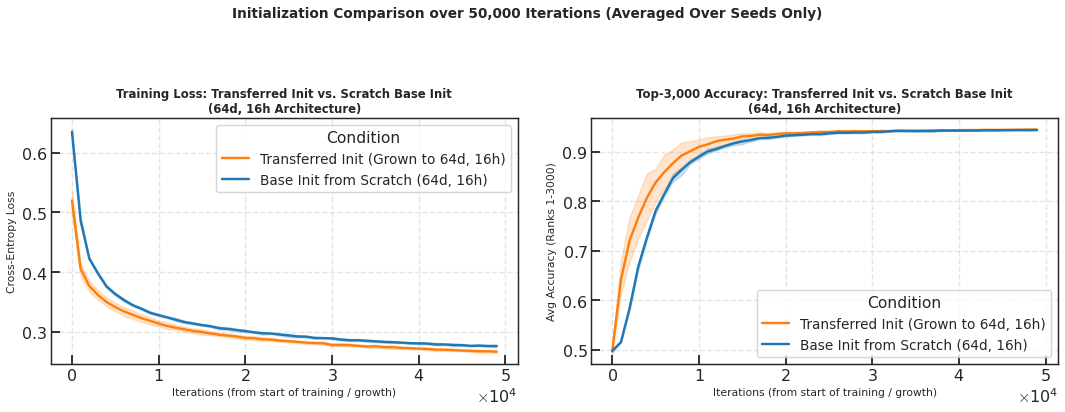

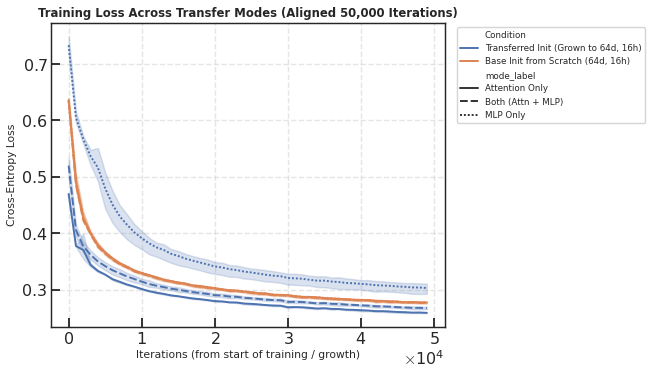

In [1]:
import os
import pickle
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import utils

# Apply standard style
utils.set_plot_style()
plt.rcParams['text.usetex'] = False

# 1. Load the summary dataframe
cache_file = "./figs/Figure_growth/growth_summary_df.pkl"
with open(cache_file, "rb") as f:
    bundle = pickle.load(f)
df = bundle["trajectory"]

# ==============================================================================
# 2. Extract & Align the Two Experimental Segments
# ==============================================================================

# Segment 1: 2nd half of Init (32d, 8h) + Both Growth (Epochs 50 - 99 / Iterations 50k - 100k)
df_growth_2nd_half = df[
    (df["condition"] == "both_growth") & 
    (df["epoch"] >= 50)
].copy()
# Align steps to start from 0 for a direct 1-to-1 comparison
df_growth_2nd_half["aligned_iteration"] = df_growth_2nd_half["iteration"] - 50000
df_growth_2nd_half["aligned_epoch"] = df_growth_2nd_half["epoch"] - 50
df_growth_2nd_half["Condition"] = "Transferred Init (Grown to 64d, 16h)"

# Segment 2: 1st half of Both [Base Init] (64d, 16h) (Epochs 0 - 49 / Iterations 0 - 50k)
df_base_1st_half = df[
    (df["condition"] == "base_both_growth") & 
    (df["epoch"] < 50)
].copy()
df_base_1st_half["aligned_iteration"] = df_base_1st_half["iteration"]
df_base_1st_half["aligned_epoch"] = df_base_1st_half["epoch"]
df_base_1st_half["Condition"] = "Base Init from Scratch (64d, 16h)"

# Combine both segments
combined_df = pd.concat([df_growth_2nd_half, df_base_1st_half], ignore_index=True)

# Format transfer mode labels
transfer_labels = {
    'both': 'Both (Attn + MLP)',
    'attn_only': 'Attention Only',
    'mlp_only': 'MLP Only'
}
combined_df["mode_label"] = combined_df["transfer_mode"].map(transfer_labels)

# ==============================================================================
# 3. Plot Comparison (Loss & Accuracy)
# ==============================================================================
fig, axs = plt.subplots(1, 2, figsize=(16, 6))

# --- Left Panel: Training Loss Comparison ---
# Filtering for the primary 'both' transfer mode (Attn + MLP transferred)
primary_df = combined_df[combined_df["transfer_mode"] == "both"]

sns.lineplot(
    data=primary_df,
    x="aligned_iteration",
    y="train_loss",
    hue="Condition",
    palette={"Transferred Init (Grown to 64d, 16h)": "#ff7f0e", 
             "Base Init from Scratch (64d, 16h)": "#1f77b4"},
    linewidth=2.5,
    ax=axs[0]
)
axs[0].set_title("Training Loss: Transferred Init vs. Scratch Base Init\n(64d, 16h Architecture)", 
                 fontsize=12, fontweight="bold")
axs[0].set_xlabel("Iterations (from start of training / growth)", fontsize=11)
axs[0].set_ylabel("Cross-Entropy Loss", fontsize=11)
axs[0].grid(True, linestyle="--", alpha=0.5)
axs[0].ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

# --- Right Panel: Top-3k Memorization Accuracy ---
sns.lineplot(
    data=primary_df,
    x="aligned_iteration",
    y="top_3k_acc",
    hue="Condition",
    palette={"Transferred Init (Grown to 64d, 16h)": "#ff7f0e", 
             "Base Init from Scratch (64d, 16h)": "#1f77b4"},
    linewidth=2.5,
    ax=axs[1]
)
axs[1].set_title("Top-3,000 Accuracy: Transferred Init vs. Scratch Base Init\n(64d, 16h Architecture)", 
                 fontsize=12, fontweight="bold")
axs[1].set_xlabel("Iterations (from start of training / growth)", fontsize=11)
axs[1].set_ylabel("Avg Accuracy (Ranks 1-3000)", fontsize=11)
axs[1].grid(True, linestyle="--", alpha=0.5)
axs[1].ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

plt.suptitle("Initialization Comparison over 50,000 Iterations (Averaged Over Seeds Only)", 
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# Optional: Plotting with Transfer Mode Breakdown (Attn Only vs MLP Only vs Both)
# ==============================================================================
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=combined_df,
    x="aligned_iteration",
    y="train_loss",
    hue="Condition",
    style="mode_label",
    linewidth=2.0
)
plt.title("Training Loss Across Transfer Modes (Aligned 50,000 Iterations)", fontsize=12, fontweight="bold")
plt.xlabel("Iterations (from start of training / growth)", fontsize=11)
plt.ylabel("Cross-Entropy Loss", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()


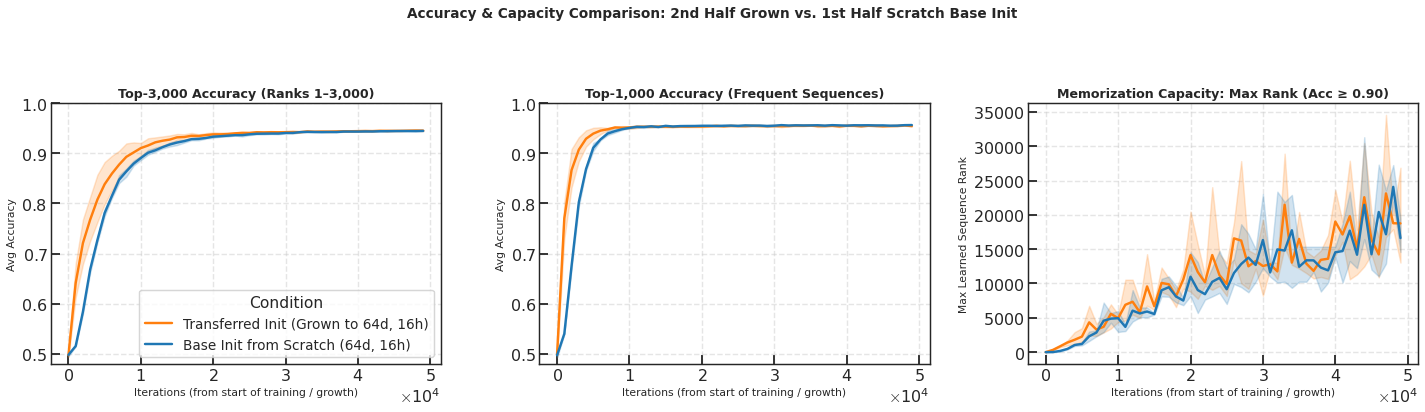

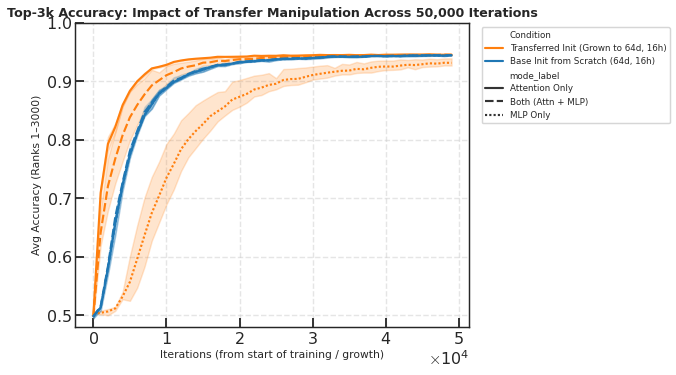

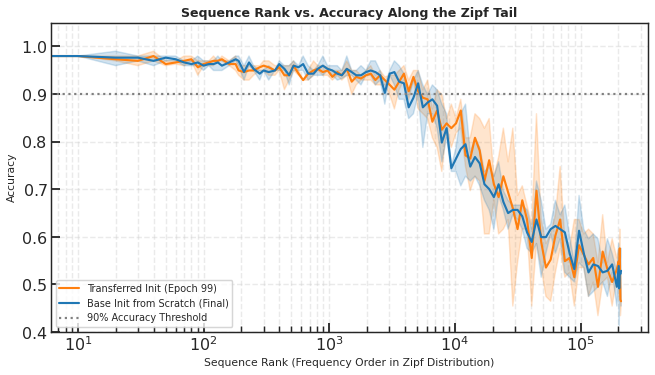

In [2]:
# ==============================================================================
# Accuracy Comparison: Transferred Init vs. Scratch Base Init (64d, 16h)
# ==============================================================================

palette = {
    "Transferred Init (Grown to 64d, 16h)": "#ff7f0e",
    "Base Init from Scratch (64d, 16h)": "#1f77b4"
}

fig, axs = plt.subplots(1, 3, figsize=(21, 6))

# --- Panel 1: Top-3,000 Sequence Accuracy ---
sns.lineplot(
    data=primary_df,
    x="aligned_iteration",
    y="top_3k_acc",
    hue="Condition",
    palette=palette,
    linewidth=2.5,
    ax=axs[0]
)
axs[0].set_title("Top-3,000 Accuracy (Ranks 1–3,000)", fontsize=13, fontweight="bold")
axs[0].set_xlabel("Iterations (from start of training / growth)", fontsize=11)
axs[0].set_ylabel("Avg Accuracy", fontsize=11)
axs[0].set_ylim(0.48, 1.0)
axs[0].grid(True, linestyle="--", alpha=0.5)
axs[0].ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

# --- Panel 2: Top-1,000 Sequence Accuracy ---
sns.lineplot(
    data=primary_df,
    x="aligned_iteration",
    y="top_1k_acc",
    hue="Condition",
    palette=palette,
    linewidth=2.5,
    ax=axs[1],
    legend=False
)
axs[1].set_title("Top-1,000 Accuracy (Frequent Sequences)", fontsize=13, fontweight="bold")
axs[1].set_xlabel("Iterations (from start of training / growth)", fontsize=11)
axs[1].set_ylabel("Avg Accuracy", fontsize=11)
axs[1].set_ylim(0.48, 1.0)
axs[1].grid(True, linestyle="--", alpha=0.5)
axs[1].ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

# --- Panel 3: Memorization Capacity (Max Rank with Accuracy >= 90%) ---
sns.lineplot(
    data=primary_df,
    x="aligned_iteration",
    y="max_rank_90",
    hue="Condition",
    palette=palette,
    linewidth=2.5,
    ax=axs[2],
    legend=False
)
axs[2].set_title("Memorization Capacity: Max Rank (Acc ≥ 0.90)", fontsize=13, fontweight="bold")
axs[2].set_xlabel("Iterations (from start of training / growth)", fontsize=11)
axs[2].set_ylabel("Max Learned Sequence Rank", fontsize=11)
axs[2].grid(True, linestyle="--", alpha=0.5)
axs[2].ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

plt.suptitle("Accuracy & Capacity Comparison: 2nd Half Grown vs. 1st Half Scratch Base Init", 
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


# ==============================================================================
# Breakdown Across All Transfer Modes (Both vs. Attn Only vs. MLP Only)
# ==============================================================================
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=combined_df,
    x="aligned_iteration",
    y="top_3k_acc",
    hue="Condition",
    style="mode_label",
    palette=palette,
    linewidth=2.2
)
plt.title("Top-3k Accuracy: Impact of Transfer Manipulation Across 50,000 Iterations", 
          fontsize=13, fontweight="bold")
plt.xlabel("Iterations (from start of training / growth)", fontsize=11)
plt.ylabel("Avg Accuracy (Ranks 1–3000)", fontsize=11)
plt.ylim(0.48, 1.0)
plt.grid(True, linestyle="--", alpha=0.5)
plt.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()


# ==============================================================================
# End-of-Period Rank-Accuracy Profile Along the Zipf Tail (1 to 30,000)
# ==============================================================================
# Compares accuracy across sequence ranks at the end of each 50k-step window:
# - Transferred Init evaluated at Epoch 99 (end of Phase 2)
# - Base Init evaluated at Epoch 49 (end of Phase 1)
df_prof = bundle["rank_profiles"]

# Transferred grown model profile at final epoch
p_growth = df_prof[
    (df_prof["condition"] == "both_growth") & 
    (df_prof["epoch"] == df_prof["epoch"].max())
].copy()
p_growth["Condition"] = "Transferred Init (Epoch 99)"

# Scratch base init profile at epoch 49
p_base = df_prof[
    (df_prof["condition"] == "base_both_growth") & 
    (df_prof["epoch"] == 49)
].copy()
# (If epoch 49 profile wasn't explicitly sampled, take its latest epoch in Phase 1 or final epoch)
if len(p_base) == 0:
    p_base = df_prof[
        (df_prof["condition"] == "base_both_growth") & 
        (df_prof["epoch"] == df_prof["epoch"].max())
    ].copy()
    p_base["Condition"] = "Base Init from Scratch (Final)"
else:
    p_base["Condition"] = "Base Init from Scratch (Epoch 49)"

prof_compare = pd.concat([p_growth, p_base], ignore_index=True)
prof_primary = prof_compare[prof_compare["transfer_mode"] == "both"]

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=prof_primary,
    x="sequence_rank",
    y="accuracy",
    hue="Condition",
    palette={"Transferred Init (Epoch 99)": "#ff7f0e",
             "Base Init from Scratch (Epoch 49)": "#1f77b4",
             "Base Init from Scratch (Final)": "#1f77b4"},
    linewidth=2.2
)
plt.axhline(0.90, color="gray", linestyle=":", label="90% Accuracy Threshold")
plt.xscale("log")
plt.title("Sequence Rank vs. Accuracy Along the Zipf Tail", fontsize=13, fontweight="bold")
plt.xlabel("Sequence Rank (Frequency Order in Zipf Distribution)", fontsize=11)
plt.ylabel("Accuracy", fontsize=11)
plt.ylim(0.4, 1.05)
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.legend(loc="lower left", fontsize=10)
plt.tight_layout()
plt.show()
